# Zeta(7): historical recovery

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
from flint import arb, ctx
from IPython.display import Markdown, display
from cmfs import (
    BorweinBradleyZeta7CMF, borwein_bradley_zeta7_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}

target = lambda: arb(7).zeta()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Borwein-Bradley (1997), proved by Almkvist-Granville (1999)

[Borwein and Bradley, equation (1.4)](https://arxiv.org/pdf/math/0505124).

The approximants truncate the two Borwein–Bradley inverse-binomial sums for $\zeta(7)$.
**CMF:** rank-15 moment extension. **Start:** $(u,v)=(0,0)$. **Direction:** $(1,0)$.
**Readout:** $S_{00}/S_{10}$ from the transported partial-sum and constant seed rows.
N is the number of summands. The v-axis is an auxiliary binomial transform; only forward steps are used.

In [5]:
cmf = BorweinBradleyZeta7CMF()
u, v = cmf.axes
start, trajectory = ({u: 0, v: 0}, {u: 1, v: 0})
seeds = borwein_bradley_zeta7_seeds()
states = cmf.walk(trajectory, DEPTHS, start, initial=seeds)
approximants = [state[0, 0] / state[1, 0] for state in states]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Borwein-Bradley (1997)'] = (DEPTHS, deltas)
accuracy['Borwein-Bradley (1997)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.823422203280


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

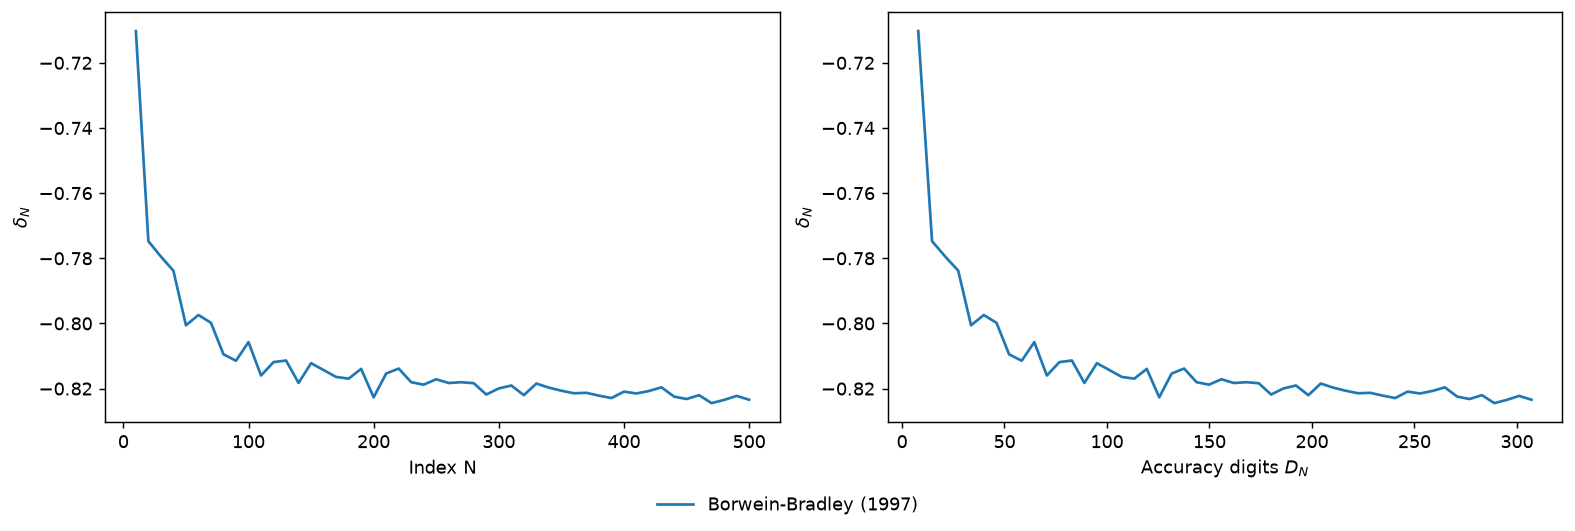

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [9]:
bounds = {
    'Borwein-Bradley (1997)': 'Exact inverse-binomial series identity; no irrationality bound',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Borwein-Bradley (1997) | Exact inverse-binomial series identity; no irrationality bound | -0.823422203280 (N = 500) |